# Chapter 1 — Common Conventions and API Elements of scikit-learn

**Sumber:** *scikit-learn Cookbook*, 3rd Ed. (John Sukup, Packt, 2025)

Chapter pertama buku ini membangun fondasi: sebelum masuk ke algoritma tertentu, kita perlu memahami *bahasa bersama* yang dipakai seluruh komponen scikit-learn. Hampir semua objek di library ini — mulai dari regresi linear, `StandardScaler`, sampai `KMeans` — mengikuti kontrak antarmuka (API) yang sama. Dengan menguasai konvensi ini, mempelajari algoritma baru cukup dengan mengganti nama kelasnya saja.

**Daftar Isi**

1. 1.1 Mengenal scikit-learn dan Prinsip Desainnya
2. 1.2 Representasi Data: Feature Matrix `X` dan Target `y`
3. 1.3 Dataset Bawaan: Loader, Generator, dan Objek `Bunch`
4. 1.4 Estimator API: `fit`, Hyperparameter, dan Atribut Hasil Belajar
5. 1.5 Predictor: `predict`, `predict_proba`, dan `score`
6. 1.6 Transformer: `fit`, `transform`, `fit_transform`, `inverse_transform`
7. 1.7 Membagi Data dengan `train_test_split` dan Mencegah Data Leakage
8. 1.8 Pipeline dan `make_pipeline`
9. 1.9 `ColumnTransformer` untuk Data Heterogen
10. 1.10 `set_output`, `set_config`, dan Tampilan HTML Estimator
11. 1.11 Menyimpan dan Memuat Model dengan `joblib`
12. 1.12 Gambaran Umum Supervised vs Unsupervised Learning

> **Catatan:** Repositori resmi penerbit tidak menyediakan notebook untuk Chapter 1, sehingga kode di notebook ini ditulis ulang berdasarkan materi yang diajarkan pada chapter tersebut. Setiap bagian berisi penjelasan teori, kode yang dapat dijalankan (diuji pada scikit-learn 1.9.1), dan interpretasi hasilnya.

## Import Library

In [1]:
%matplotlib inline
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import scipy
from scipy import sparse

import sklearn
from sklearn import datasets
from sklearn.base import clone
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder, MinMaxScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.compose import ColumnTransformer, make_column_transformer, make_column_selector
from sklearn.metrics import accuracy_score, r2_score

RANDOM_STATE = 42  # seed global agar hasil dapat direproduksi
np.random.seed(RANDOM_STATE)
plt.rcParams["figure.figsize"] = (7, 4)

print("scikit-learn :", sklearn.__version__)
print("numpy        :", np.__version__)
print("pandas       :", pd.__version__)
print("scipy        :", scipy.__version__)

scikit-learn : 1.9.1
numpy        : 2.5.3
pandas       : 3.0.6
scipy        : 1.18.1


## 1.1 Mengenal scikit-learn dan Prinsip Desainnya

**Teori:**

scikit-learn adalah library *machine learning* open-source untuk Python yang dibangun di atas NumPy, SciPy, dan joblib. Fokusnya adalah *classical machine learning* (bukan deep learning): regresi, klasifikasi, clustering, reduksi dimensi, seleksi model, dan preprocessing. Kekuatan utamanya bukan pada satu algoritma tertentu, melainkan pada **API yang seragam**.

Desain API scikit-learn dirumuskan dalam makalah Buitinck dkk. (2013), *"API design for machine learning software: experiences from the scikit-learn project"*. Lima prinsip utamanya:

| Prinsip | Makna | Contoh nyata |
|---|---|---|
| **Consistency** | Semua objek berbagi antarmuka yang terbatas dan konsisten. | Semua model punya `fit()`; semua transformer punya `transform()`. |
| **Inspection** | Hyperparameter dan parameter hasil belajar disimpan sebagai atribut publik. | `model.C`, `model.coef_`, `scaler.mean_`. |
| **Non-proliferation of classes** | Data direpresentasikan dengan tipe standar (array NumPy, DataFrame, matriks sparse SciPy), bukan kelas khusus. | `X` cukup berupa `np.ndarray`, tidak perlu objek `Dataset` khusus. |
| **Composition** | Algoritma kompleks disusun dari blok-blok sederhana. | `Pipeline`, `ColumnTransformer`, `GridSearchCV`. |
| **Sensible defaults** | Setiap hyperparameter punya nilai default yang masuk akal. | `RandomForestClassifier()` langsung bisa dipakai tanpa argumen. |

Dari prinsip tersebut lahir tiga **antarmuka (interface)** inti:

1. **Estimator** — objek apa pun yang belajar dari data lewat `fit(X, y)`.
2. **Predictor** — estimator yang dapat menghasilkan prediksi lewat `predict(X)` (dan sering `predict_proba`, `score`).
3. **Transformer** — estimator yang dapat mengubah data lewat `transform(X)`.

Secara matematis, sebuah model supervised berusaha menemukan fungsi $\hat{f}$ dari keluarga fungsi $\mathcal{F}$ yang meminimalkan *risiko empiris*:

$$
\hat{f} = \arg\min_{f \in \mathcal{F}} \; \frac{1}{n} \sum_{i=1}^{n} L\big(y_i, f(\mathbf{x}_i)\big) + \lambda\,\Omega(f)
$$

dengan $L$ fungsi loss, $\Omega$ regularisasi, dan $\lambda$ kekuatannya. Dalam scikit-learn: pilihan $\mathcal{F}$, $L$, dan $\lambda$ ditentukan lewat **hyperparameter** di konstruktor, proses $\arg\min$ dijalankan oleh `fit()`, dan $\hat{f}$ yang dihasilkan disimpan di **atribut bertanda underscore** (misalnya `coef_`).

In [2]:
# Prinsip "consistency": tiga algoritma berbeda, pola kode yang identik
X_demo, y_demo = datasets.load_iris(return_X_y=True)

for model in [LogisticRegression(max_iter=1000),
              KNeighborsClassifier(),
              DecisionTreeClassifier(random_state=RANDOM_STATE)]:
    model.fit(X_demo, y_demo)                   # belajar
    acc = model.score(X_demo, y_demo)           # evaluasi (akurasi data latih)
    print(f"{type(model).__name__:<24} akurasi train = {acc:.3f}")

# Prinsip "sensible defaults" & "inspection": cek beberapa hyperparameter default
knn = KNeighborsClassifier()
print("\nDefault KNN -> n_neighbors =", knn.n_neighbors, "| weights =", knn.weights, "| metric =", knn.metric)

LogisticRegression       akurasi train = 0.973
KNeighborsClassifier     akurasi train = 0.967
DecisionTreeClassifier   akurasi train = 1.000

Default KNN -> n_neighbors = 5 | weights = uniform | metric = minkowski


**Interpretasi:** Tiga algoritma yang sangat berbeda (model linear, berbasis jarak, dan berbasis pohon) dilatih dan dievaluasi dengan dua baris kode yang **persis sama**. Inilah inti prinsip *consistency*. Akurasi train `DecisionTreeClassifier` = 1.000 karena pohon tanpa batas kedalaman dapat menghafal data latih — ini sinyal awal potensi *overfitting* yang akan diuji dengan data terpisah di bagian 1.7. Default `KNeighborsClassifier` (`n_neighbors=5`, jarak Minkowski/Euclidean) sudah langsung dapat dipakai, sesuai prinsip *sensible defaults*.

## 1.2 Representasi Data: Feature Matrix `X` dan Target `y`

**Teori:**

scikit-learn memakai konvensi data tabular yang sangat ketat:

- **Feature matrix** $\mathbf{X} \in \mathbb{R}^{n \times p}$ berbentuk `(n_samples, n_features)`. Setiap **baris** adalah satu sampel/observasi, setiap **kolom** adalah satu fitur.
- **Target vector** $\mathbf{y} \in \mathbb{R}^{n}$ berbentuk `(n_samples,)` — label kelas (klasifikasi) atau nilai kontinu (regresi). Untuk masalah multi-output, `y` berbentuk `(n_samples, n_outputs)`.

$$
\mathbf{X} =
\begin{bmatrix}
x_{11} & x_{12} & \cdots & x_{1p} \\
x_{21} & x_{22} & \cdots & x_{2p} \\
\vdots & \vdots & \ddots & \vdots \\
x_{n1} & x_{n2} & \cdots & x_{np}
\end{bmatrix},
\qquad
\mathbf{y} =
\begin{bmatrix} y_1 \\ y_2 \\ \vdots \\ y_n \end{bmatrix}
$$

Tipe input yang diterima (prinsip *non-proliferation of classes*):

| Tipe | Kapan digunakan | Catatan |
|---|---|---|
| `numpy.ndarray` | Data numerik padat (dense) | Format "asli" scikit-learn. |
| `pandas.DataFrame` | Data tabular dengan nama kolom | Nama kolom disimpan di `feature_names_in_`. |
| `scipy.sparse` (CSR/CSC) | Data dengan sangat banyak nol (mis. teks bag-of-words) | Hemat memori: hanya menyimpan elemen non-nol. |
| list Python | Prototipe kecil | Otomatis dikonversi ke array. |

Kesalahan paling umum pemula adalah memberikan **satu fitur sebagai array 1D** berbentuk `(n,)`. scikit-learn akan menolak dengan error karena `X` harus 2D; solusinya `x.reshape(-1, 1)`.

Untuk matriks sparse, *density* didefinisikan sebagai
$$
\text{density} = \frac{\text{nnz}}{n \times p},
$$
dengan nnz = jumlah elemen non-nol. Jika density kecil, format CSR menghemat memori kira-kira dari $O(np)$ menjadi $O(\text{nnz})$.

In [3]:
# 1) NumPy array
X_np = np.array([[5.1, 3.5, 1.4],
                 [4.9, 3.0, 1.4],
                 [6.2, 3.4, 5.4],
                 [5.9, 3.0, 5.1]])
y_np = np.array([0, 0, 1, 1])
print("X shape:", X_np.shape, "-> (n_samples, n_features)")
print("y shape:", y_np.shape, "-> (n_samples,)")

# 2) pandas DataFrame: nama kolom ikut tersimpan di estimator
X_df = pd.DataFrame(X_np, columns=["sepal_len", "sepal_wid", "petal_len"])
clf = LogisticRegression().fit(X_df, y_np)
print("\nfeature_names_in_:", clf.feature_names_in_)
print("n_features_in_   :", clf.n_features_in_)

# 3) Kesalahan umum: satu fitur sebagai array 1D
x_1d = np.array([1.0, 2.0, 3.0, 4.0])
try:
    LinearRegression().fit(x_1d, [2.0, 4.0, 6.0, 8.0])
except ValueError as e:
    print("\nError 1D :", str(e).splitlines()[0])
lr = LinearRegression().fit(x_1d.reshape(-1, 1), [2.0, 4.0, 6.0, 8.0])
print("Setelah reshape(-1, 1) -> shape", x_1d.reshape(-1, 1).shape, "| koefisien =", lr.coef_)

X shape: (4, 3) -> (n_samples, n_features)
y shape: (4,) -> (n_samples,)

feature_names_in_: ['sepal_len' 'sepal_wid' 'petal_len']
n_features_in_   : 3

Error 1D : Expected 2D array, got 1D array instead:
Setelah reshape(-1, 1) -> shape (4, 1) | koefisien = [2.]


In [4]:
# 4) Matriks sparse SciPy: kebanyakan elemen bernilai nol
rng = np.random.default_rng(RANDOM_STATE)
dense = rng.random((1000, 500))
dense[dense < 0.98] = 0.0               # ~98% elemen menjadi nol
X_sparse = sparse.csr_matrix(dense)
y_sparse = (np.asarray(X_sparse.sum(axis=1)).ravel() > np.median(np.asarray(X_sparse.sum(axis=1)))).astype(int)

density = X_sparse.nnz / np.prod(X_sparse.shape)
mem_dense = dense.nbytes / 1e6
mem_sparse = (X_sparse.data.nbytes + X_sparse.indices.nbytes + X_sparse.indptr.nbytes) / 1e6
print(f"Density           : {density:.4f}")
print(f"Memori dense      : {mem_dense:.2f} MB")
print(f"Memori sparse CSR : {mem_sparse:.2f} MB")

# Estimator menerima input sparse secara langsung
clf_sp = LogisticRegression(max_iter=1000).fit(X_sparse, y_sparse)
print("Akurasi train pada input sparse:", round(clf_sp.score(X_sparse, y_sparse), 3))

Density           : 0.0201


Memori dense      : 4.00 MB
Memori sparse CSR : 0.12 MB
Akurasi train pada input sparse: 0.993


**Interpretasi:** `X` selalu 2D `(4, 3)` dan `y` 1D `(4,)`. Ketika dilatih dengan DataFrame, estimator otomatis mencatat `feature_names_in_` dan `n_features_in_` — berguna untuk validasi (scikit-learn akan memperingatkan jika nama kolom saat prediksi berbeda). Memberi array 1D sebagai `X` memicu `ValueError` yang secara eksplisit menyarankan `reshape(-1, 1)`; setelah di-reshape, regresi menemukan koefisien 2 (karena $y = 2x$). Pada contoh sparse, hanya sekitar 2% elemen yang non-nol sehingga format CSR memakai memori jauh lebih kecil daripada array dense, dan `LogisticRegression` dapat dilatih langsung tanpa konversi.

## 1.3 Dataset Bawaan: Loader, Generator, dan Objek `Bunch`

**Teori:**

Modul `sklearn.datasets` menyediakan tiga kelompok sumber data:

| Kelompok | Fungsi | Sifat |
|---|---|---|
| **Toy datasets (loader)** | `load_iris`, `load_diabetes`, `load_wine`, `load_breast_cancer`, `load_digits` | Kecil, ikut terpasang bersama library, tanpa internet. |
| **Real-world (fetcher)** | `fetch_california_housing`, `fetch_openml`, `fetch_20newsgroups` | Diunduh dari internet lalu di-cache. |
| **Generator sintetis** | `make_classification`, `make_regression`, `make_blobs`, `make_moons` | Data buatan dengan sifat yang dapat dikontrol. |

Loader mengembalikan objek **`Bunch`** — subclass `dict` yang isinya juga bisa diakses sebagai atribut (`data.target` sama dengan `data["target"]`). Kunci yang umum: `data`, `target`, `feature_names`, `target_names`, `DESCR`, dan `frame` (bila `as_frame=True`). Dua opsi penting:

- `return_X_y=True` → langsung mengembalikan tuple `(X, y)`.
- `as_frame=True` → `X` berupa `DataFrame` dan `y` berupa `Series`.

**Generator sintetis** sangat berguna untuk eksperimen terkontrol karena kita tahu "kebenaran" di balik data. Misalnya `make_regression` membangkitkan
$$
y = \mathbf{X}\boldsymbol{\beta} + \beta_0 + \varepsilon, \qquad \varepsilon \sim \mathcal{N}(0, \sigma^2),
$$
dengan $\sigma$ = parameter `noise`, dan hanya `n_informative` koefisien yang tidak nol. `make_blobs` membangkitkan klaster Gaussian isotropik $\mathbf{x} \sim \mathcal{N}(\boldsymbol{\mu}_k, \sigma_k^2 \mathbf{I})$, sedangkan `make_classification` menempatkan klaster pada titik-titik sudut *hypercube* dan menambahkan fitur informatif, redundan (kombinasi linear), dan noise. Semua generator menerima `random_state` agar dapat direproduksi.

In [5]:
# Loader: objek Bunch
iris = datasets.load_iris()
print("Tipe objek :", type(iris).__name__)
print("Kunci      :", list(iris.keys()))
print("Fitur      :", iris.feature_names)
print("Kelas      :", iris.target_names)
print("data shape :", iris.data.shape, "| target shape:", iris.target.shape)
print("Akses atribut == akses dict ?", iris.target is iris["target"])

# as_frame=True -> DataFrame & Series (load_diabetes, data regresi)
X_diab, y_diab = datasets.load_diabetes(return_X_y=True, as_frame=True)
print("\nDiabetes X:", type(X_diab).__name__, X_diab.shape, "| y:", type(y_diab).__name__)
X_diab.head()

Tipe objek : Bunch
Kunci      : ['data', 'target', 'frame', 'target_names', 'DESCR', 'feature_names', 'filename', 'data_module']
Fitur      : ['sepal length (cm)', 'sepal width (cm)', 'petal length (cm)', 'petal width (cm)']
Kelas      : ['setosa' 'versicolor' 'virginica']
data shape : (150, 4) | target shape: (150,)
Akses atribut == akses dict ? True

Diabetes X: DataFrame (442, 10) | y: Series


,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6
0,0.038076,0.050680,0.061696,0.021872,-0.044223,-0.034821,-0.043401,-0.002592,0.019907,-0.017646
1,-0.001882,-0.044642,-0.051474,-0.026328,-0.008449,-0.019163,0.074412,-0.039493,-0.068332,-0.092204
2,0.085299,0.050680,0.044451,-0.005670,-0.045599,-0.034194,-0.032356,-0.002592,0.002861,-0.025930
3,-0.089063,-0.044642,-0.011595,-0.036656,0.012191,0.024991,-0.036038,0.034309,0.022688,-0.009362
4,0.005383,-0.044642,-0.036385,0.021872,0.003935,0.015596,0.008142,-0.002592,-0.031988,-0.046641


make_classification: (500, 6) | proporsi kelas: [0.698 0.302]
make_regression    : (200, 5) | koefisien asli: [ 0.    0.    0.   10.46 16.75]
make_blobs         : (300, 2) | jumlah per klaster: [100 100 100]


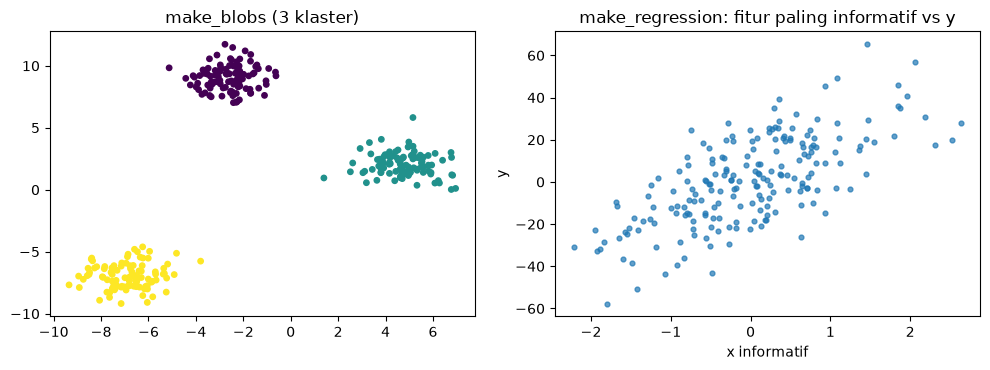

In [6]:
# Generator sintetis
X_cls, y_cls = datasets.make_classification(
    n_samples=500, n_features=6, n_informative=3, n_redundant=1,
    n_classes=2, weights=[0.7, 0.3], random_state=RANDOM_STATE)
X_reg, y_reg, true_coef = datasets.make_regression(
    n_samples=200, n_features=5, n_informative=2, noise=10.0,
    coef=True, random_state=RANDOM_STATE)
X_blob, y_blob = datasets.make_blobs(
    n_samples=300, centers=3, cluster_std=1.0, random_state=RANDOM_STATE)

print("make_classification:", X_cls.shape, "| proporsi kelas:", np.bincount(y_cls) / len(y_cls))
print("make_regression    :", X_reg.shape, "| koefisien asli:", np.round(true_coef, 2))
print("make_blobs         :", X_blob.shape, "| jumlah per klaster:", np.bincount(y_blob))

fig, axes = plt.subplots(1, 2, figsize=(10, 3.8))
axes[0].scatter(X_blob[:, 0], X_blob[:, 1], c=y_blob, cmap="viridis", s=15)
axes[0].set_title("make_blobs (3 klaster)")
axes[1].scatter(X_reg[:, np.argmax(np.abs(true_coef))], y_reg, s=12, alpha=0.7)
axes[1].set_title("make_regression: fitur paling informatif vs y")
axes[1].set_xlabel("x informatif"); axes[1].set_ylabel("y")
plt.tight_layout(); plt.show()

**Interpretasi:** `load_iris()` mengembalikan `Bunch` dengan 150 sampel × 4 fitur dan 3 kelas; `iris.target` dan `iris["target"]` menunjuk objek yang sama, membuktikan `Bunch` adalah dict yang bisa diakses seperti atribut. Dengan `as_frame=True`, data diabetes langsung menjadi `DataFrame` berkolom bernama (fitur-fiturnya sudah di-*center* dan di-*scale* oleh penyedia data). Pada generator, `weights=[0.7, 0.3]` menghasilkan data tidak seimbang (~70/30), `make_regression` hanya memiliki 2 koefisien non-nol (sesuai `n_informative=2`), dan `make_blobs` membentuk tiga gumpalan yang terpisah jelas — cocok untuk menguji clustering di bagian 1.12. Plot kanan menunjukkan hubungan linear yang kuat antara fitur informatif dan `y`, dengan sebaran akibat `noise=10`.

## 1.4 Estimator API: `fit`, Hyperparameter, dan Atribut Hasil Belajar

**Teori:**

**Estimator** adalah objek apa pun yang mempelajari sesuatu dari data melalui metode `fit(X, y=None)`. Konvensi yang harus dipahami:

1. **Hyperparameter ditentukan di `__init__`.** Konstruktor *hanya* menyimpan argumen apa adanya sebagai atribut, tanpa validasi atau komputasi. Validasi dilakukan saat `fit`.
2. **`fit` mengembalikan `self`.** Karena itu kita bisa menulis berantai: `model = Estimator().fit(X, y)`.
3. **Atribut hasil belajar diakhiri underscore (`_`)**, misalnya `coef_`, `intercept_`, `classes_`, `n_iter_`, `mean_`. Atribut ini hanya ada *setelah* `fit`. Mengaksesnya sebelum fit memicu `NotFittedError` (dari `AttributeError`).
4. **`get_params()` / `set_params()`** membaca dan mengubah hyperparameter secara terprogram. Ini fondasi bagi `GridSearchCV`, yang perlu mencoba banyak kombinasi hyperparameter.
5. **`clone()`** membuat salinan estimator dengan hyperparameter sama tetapi **belum dilatih** (tanpa atribut `_`). Dipakai di cross-validation agar setiap fold mulai dari kondisi bersih.

Perbedaan **parameter** vs **hyperparameter**:

| | Hyperparameter | Parameter (model) |
|---|---|---|
| Ditentukan oleh | Pengguna (sebelum training) | Algoritma (saat training) |
| Lokasi di scikit-learn | Argumen `__init__`, mis. `fit_intercept` | Atribut `_`, mis. `coef_` |
| Contoh pada regresi linear | `fit_intercept`, `positive` | $\boldsymbol{\beta}$ dan $\beta_0$ |

Untuk `LinearRegression`, `fit` menyelesaikan masalah *Ordinary Least Squares*:
$$
\hat{\boldsymbol{\beta}} = \arg\min_{\boldsymbol{\beta}} \lVert \mathbf{y} - \mathbf{X}\boldsymbol{\beta} \rVert_2^2
= (\mathbf{X}^\top \mathbf{X})^{-1}\mathbf{X}^\top \mathbf{y},
$$
lalu menyimpan $\hat{\boldsymbol{\beta}}$ di `coef_` dan intersep di `intercept_`.

In [7]:
from sklearn.exceptions import NotFittedError

# Hyperparameter ditetapkan di konstruktor
reg = LinearRegression(fit_intercept=True)

# Sebelum fit: atribut hasil belajar belum ada
try:
    reg.coef_
except AttributeError as e:
    print("Sebelum fit ->", type(e).__name__)
try:
    reg.predict(X_reg)
except NotFittedError as e:
    print("predict sebelum fit ->", type(e).__name__)

# fit() mengembalikan self -> bisa dirantai
returned = reg.fit(X_reg, y_reg)
print("\nfit() mengembalikan objek yang sama?", returned is reg)

# Atribut hasil belajar (trailing underscore)
print("coef_ hasil estimasi :", np.round(reg.coef_, 2))
print("coef_ sebenarnya     :", np.round(true_coef, 2))
print("intercept_           :", round(reg.intercept_, 3))
print("n_features_in_       :", reg.n_features_in_)

# Verifikasi dengan rumus normal equation (dengan kolom 1 untuk intersep)
X_aug = np.column_stack([np.ones(len(X_reg)), X_reg])
beta_ne = np.linalg.solve(X_aug.T @ X_aug, X_aug.T @ y_reg)
print("Normal equation      :", np.round(beta_ne[1:], 2), "| intercept:", round(beta_ne[0], 3))

Sebelum fit -> AttributeError
predict sebelum fit -> NotFittedError

fit() mengembalikan objek yang sama? True
coef_ hasil estimasi : [ 0.42  0.13  0.54 11.13 16.25]
coef_ sebenarnya     : [ 0.    0.    0.   10.46 16.75]
intercept_           : 1.278
n_features_in_       : 5
Normal equation      : [ 0.42  0.13  0.54 11.13 16.25] | intercept: 1.278


In [8]:
# get_params / set_params / clone
logreg = LogisticRegression(C=0.5, max_iter=500, random_state=RANDOM_STATE)
params = logreg.get_params()
print("Beberapa hyperparameter:", {k: params[k] for k in ["C", "max_iter", "solver", "tol"]})

logreg.set_params(C=2.0)                 # set_params juga mengembalikan self
print("Setelah set_params, C =", logreg.C)

logreg.fit(X_cls, y_cls)
logreg_copy = clone(logreg)
print("\nAsli punya coef_?  ", hasattr(logreg, "coef_"))
print("Clone punya coef_? ", hasattr(logreg_copy, "coef_"))
print("Hyperparameter clone sama?", logreg_copy.get_params() == logreg.get_params())

Beberapa hyperparameter: {'C': 0.5, 'max_iter': 500, 'solver': 'lbfgs', 'tol': 0.0001}
Setelah set_params, C = 2.0

Asli punya coef_?   True
Clone punya coef_?  False
Hyperparameter clone sama? True


**Interpretasi:** Sebelum `fit`, atribut `coef_` belum ada dan `predict` memicu `NotFittedError` — estimator benar-benar "kosong". `fit()` mengembalikan objek yang sama (`True`), sehingga pola berantai valid. Koefisien hasil estimasi sangat dekat dengan koefisien asli dari `make_regression` (dua koefisien besar, tiga mendekati nol), dan hasilnya identik dengan solusi *normal equation* yang dihitung manual, menunjukkan bahwa `fit` memang menyelesaikan OLS. Pada bagian kedua, `set_params` mengubah `C` dari 0.5 ke 2.0, dan `clone` menghasilkan estimator dengan hyperparameter identik tetapi tanpa `coef_` — salinan "segar" yang belum dilatih.

## 1.5 Predictor: `predict`, `predict_proba`, dan `score`

**Teori:**

**Predictor** adalah estimator yang, setelah dilatih, dapat menghasilkan keluaran untuk data baru:

| Metode | Keluaran | Ketersediaan |
|---|---|---|
| `predict(X)` | Label kelas / nilai kontinu, shape `(n_samples,)` | Semua predictor |
| `predict_proba(X)` | Probabilitas tiap kelas, shape `(n_samples, n_classes)`, tiap baris berjumlah 1 | Classifier probabilistik |
| `predict_log_proba(X)` | $\log$ dari probabilitas | Sebagian classifier |
| `decision_function(X)` | Skor kepercayaan mentah (mis. jarak ke hyperplane) | Model linear, SVM |
| `score(X, y)` | Satu angka metrik default | Semua predictor |

Metrik default `score`:

- **Classifier → akurasi**: $\displaystyle \text{Acc} = \frac{1}{n}\sum_{i=1}^{n}\mathbb{1}(\hat{y}_i = y_i)$
- **Regressor → koefisien determinasi** $R^2$: $\displaystyle R^2 = 1 - \frac{\sum_i (y_i - \hat{y}_i)^2}{\sum_i (y_i - \bar{y})^2}$. Nilai 1 berarti sempurna, 0 berarti setara dengan memprediksi rata-rata, dan bisa negatif jika lebih buruk dari rata-rata.

Pada **regresi logistik** biner, probabilitas diperoleh dari fungsi sigmoid terhadap skor linear $z = \mathbf{w}^\top\mathbf{x} + b$ (inilah `decision_function`):
$$
P(y=1 \mid \mathbf{x}) = \sigma(z) = \frac{1}{1 + e^{-z}},
$$
dan `predict` memilih kelas dengan probabilitas terbesar, yang ekuivalen dengan $\hat{y} = \mathbb{1}(z > 0)$, yaitu ambang probabilitas 0.5. Urutan kolom `predict_proba` mengikuti atribut `classes_`.

In [9]:
X_tr_c, X_te_c, y_tr_c, y_te_c = train_test_split(
    X_cls, y_cls, test_size=0.25, stratify=y_cls, random_state=RANDOM_STATE)

clf = LogisticRegression(max_iter=1000, random_state=RANDOM_STATE).fit(X_tr_c, y_tr_c)

y_pred = clf.predict(X_te_c[:5])
proba = clf.predict_proba(X_te_c[:5])
z = clf.decision_function(X_te_c[:5])

hasil = pd.DataFrame({
    "decision_function (z)": z.round(3),
    "sigmoid(z)": (1 / (1 + np.exp(-z))).round(3),
    "P(kelas 0)": proba[:, 0].round(3),
    "P(kelas 1)": proba[:, 1].round(3),
    "predict": y_pred,
    "y asli": y_te_c[:5],
})
print("classes_:", clf.classes_)
print("Jumlah tiap baris predict_proba:", proba.sum(axis=1))
hasil

classes_: [0 1]
Jumlah tiap baris predict_proba: [1. 1. 1. 1. 1.]


,decision_function (z),sigmoid(z),P(kelas 0),P(kelas 1),predict,y asli
0,-0.403,0.401,0.599,0.401,0,1
1,-2.714,0.062,0.938,0.062,0,0
2,-3.349,0.034,0.966,0.034,0,0
3,-4.673,0.009,0.991,0.009,0,0
4,-5.237,0.005,0.995,0.005,0,0


In [10]:
# score() == metrik default
print("Classifier score   :", round(clf.score(X_te_c, y_te_c), 4))
print("accuracy_score     :", round(accuracy_score(y_te_c, clf.predict(X_te_c)), 4))

X_tr_r, X_te_r, y_tr_r, y_te_r = train_test_split(X_reg, y_reg, test_size=0.25, random_state=RANDOM_STATE)
reg = LinearRegression().fit(X_tr_r, y_tr_r)
y_hat = reg.predict(X_te_r)
r2_manual = 1 - np.sum((y_te_r - y_hat) ** 2) / np.sum((y_te_r - y_te_r.mean()) ** 2)
print("\nRegressor score    :", round(reg.score(X_te_r, y_te_r), 4))
print("r2_score           :", round(r2_score(y_te_r, y_hat), 4))
print("R^2 manual (rumus) :", round(r2_manual, 4))

Classifier score   : 0.84
accuracy_score     : 0.84

Regressor score    : 0.7835
r2_score           : 0.7835
R^2 manual (rumus) : 0.7835


**Interpretasi:** Tabel menunjukkan hubungan antar-metode predictor: kolom `sigmoid(z)` yang dihitung manual dari `decision_function` identik dengan `P(kelas 1)` dari `predict_proba`, dan `predict` bernilai 1 tepat ketika $z > 0$ (probabilitas > 0.5). Setiap baris probabilitas berjumlah 1. Pada bagian kedua, `score` classifier sama persis dengan `accuracy_score`, dan `score` regressor sama dengan `r2_score` maupun rumus $R^2$ manual. $R^2 pprox 0.78$ berarti model menjelaskan sekitar 78% variansi `y` di data uji; sisanya berasal dari `noise=10` yang sengaja ditambahkan dan memang tidak dapat diprediksi oleh model apa pun.

## 1.6 Transformer: `fit`, `transform`, `fit_transform`, `inverse_transform`

**Teori:**

**Transformer** adalah estimator yang mengubah representasi data. Pola kerjanya dua tahap:

1. `fit(X)` — **mempelajari statistik** dari data (mis. rata-rata dan simpangan baku), disimpan di atribut `_`.
2. `transform(X)` — **menerapkan** transformasi memakai statistik yang sudah dipelajari.

`fit_transform(X)` adalah gabungan keduanya (kadang lebih efisien). `inverse_transform` mengembalikan data ke ruang asli bila transformasinya dapat dibalik.

Contoh: **`StandardScaler`** (standardisasi z-score) mempelajari $\mu_j$ dan $\sigma_j$ setiap fitur $j$:
$$
z_{ij} = \frac{x_{ij} - \mu_j}{\sigma_j}, \qquad
\mu_j = \frac{1}{n}\sum_{i} x_{ij}, \quad
\sigma_j = \sqrt{\frac{1}{n}\sum_{i}(x_{ij}-\mu_j)^2}
$$
(perhatikan scikit-learn memakai simpangan baku populasi, pembagi $n$). Inversnya: $x_{ij} = z_{ij}\,\sigma_j + \mu_j$.

**`MinMaxScaler`** memetakan ke rentang $[0, 1]$: $x' = \dfrac{x - x_{\min}}{x_{\max} - x_{\min}}$.

**Aturan emas — hindari data leakage:** statistik transformasi ($\mu$, $\sigma$, min, max, kategori, dsb.) **hanya boleh dipelajari dari data latih**. Data uji cukup di-`transform` memakai statistik data latih. Jika kita `fit` pada seluruh data, informasi dari data uji "bocor" ke proses training sehingga estimasi performa menjadi terlalu optimistis.

| Data | Metode yang dipanggil |
|---|---|
| Train | `fit_transform(X_train)` |
| Test / data produksi | `transform(X_test)` saja |

In [11]:
X_tr_i, X_te_i, y_tr_i, y_te_i = train_test_split(
    iris.data, iris.target, test_size=0.3, stratify=iris.target, random_state=RANDOM_STATE)

scaler = StandardScaler()
X_tr_s = scaler.fit_transform(X_tr_i)    # fit HANYA pada data latih
X_te_s = scaler.transform(X_te_i)        # test hanya di-transform

print("mean_  (dipelajari dari train):", scaler.mean_.round(3))
print("scale_ (sigma, pembagi n)     :", scaler.scale_.round(3))
print("sigma manual np.std(ddof=0)   :", X_tr_i.std(axis=0, ddof=0).round(3))

print("\nTrain setelah scaling -> mean:", X_tr_s.mean(axis=0).round(3), "| std:", X_tr_s.std(axis=0).round(3))
print("Test  setelah scaling -> mean:", X_te_s.mean(axis=0).round(3), "| std:", X_te_s.std(axis=0).round(3))

# inverse_transform mengembalikan ke skala asli
X_back = scaler.inverse_transform(X_te_s)
print("\ninverse_transform == data asli?", np.allclose(X_back, X_te_i))

# MinMaxScaler untuk perbandingan
mm = MinMaxScaler().fit(X_tr_i)
print("MinMax train range:", mm.transform(X_tr_i).min().round(3), "-", mm.transform(X_tr_i).max().round(3))
print("MinMax test range :", mm.transform(X_te_i).min().round(3), "-", mm.transform(X_te_i).max().round(3))

mean_  (dipelajari dari train): [5.873 3.055 3.785 1.206]
scale_ (sigma, pembagi n)     : [0.859 0.455 1.776 0.774]
sigma manual np.std(ddof=0)   : [0.859 0.455 1.776 0.774]

Train setelah scaling -> mean: [ 0. -0. -0. -0.] | std: [1. 1. 1. 1.]
Test  setelah scaling -> mean: [-0.116  0.015 -0.05  -0.027] | std: [0.858 0.839 0.968 0.937]

inverse_transform == data asli? True
MinMax train range: 0.0 - 1.0
MinMax test range : -0.017 - 0.958


**Interpretasi:** `scale_` sama dengan `np.std(ddof=0)`, mengonfirmasi bahwa `StandardScaler` memakai simpangan baku populasi. Data latih hasil scaling memiliki mean tepat 0 dan std tepat 1, sedangkan data uji **tidak** tepat 0/1 — dan memang seharusnya begitu, karena data uji ditransformasi dengan statistik data latih (mensimulasikan data baru yang belum pernah dilihat). `inverse_transform` mengembalikan nilai asli secara presisi. Pada `MinMaxScaler`, rentang data latih tepat [0, 1], tetapi data uji bisa sedikit keluar dari rentang itu; ini wajar dan merupakan bukti tidak ada kebocoran informasi dari test ke train.

## 1.7 Membagi Data dengan `train_test_split` dan Mencegah Data Leakage

**Teori:**

Tujuan machine learning adalah **generalisasi**: performa baik pada data yang *belum pernah dilihat*. Mengukur performa pada data latih menghasilkan estimasi yang bias (terlalu optimistis), terutama untuk model fleksibel yang dapat menghafal. Karena itu data dibagi:

$$
\mathcal{D} = \mathcal{D}_{\text{train}} \cup \mathcal{D}_{\text{test}}, \qquad \mathcal{D}_{\text{train}} \cap \mathcal{D}_{\text{test}} = \varnothing
$$

Parameter penting `train_test_split`:

| Parameter | Fungsi |
|---|---|
| `test_size` / `train_size` | Proporsi (float) atau jumlah (int) data uji/latih. Default `test_size=0.25`. |
| `random_state` | Seed pengacakan agar pembagian dapat direproduksi. |
| `shuffle` | Acak sebelum dibagi (default `True`; set `False` untuk deret waktu). |
| `stratify` | Mempertahankan proporsi kelas yang sama di train dan test. |

**Stratifikasi** penting untuk data tidak seimbang. Tanpa stratifikasi, proporsi kelas minoritas di test bisa menyimpang jauh dari populasinya sehingga evaluasi tidak representatif. Dengan `stratify=y`, untuk setiap kelas $k$:
$$
\frac{n_{k}^{\text{test}}}{n^{\text{test}}} \approx \frac{n_{k}}{n}.
$$

**Gap generalisasi** $= \text{skor}_{\text{train}} - \text{skor}_{\text{test}}$. Gap besar mengindikasikan *overfitting*; skor rendah di keduanya mengindikasikan *underfitting*.

**Data leakage** terjadi ketika informasi dari luar data latih (khususnya dari data uji) ikut memengaruhi training — misalnya melakukan scaling/imputasi/seleksi fitur pada seluruh dataset sebelum split. Solusinya: split terlebih dahulu, lalu lakukan semua `fit` hanya pada train (paling aman menggunakan `Pipeline`, bagian 1.8).

In [12]:
# Data tidak seimbang: 90% kelas 0, 10% kelas 1
X_imb, y_imb = datasets.make_classification(
    n_samples=200, n_features=5, weights=[0.9, 0.1], flip_y=0, random_state=RANDOM_STATE)
print("Proporsi kelas 1 (keseluruhan):", y_imb.mean().round(3))

rows = []
for seed in range(5):
    _, _, _, yt_plain = train_test_split(X_imb, y_imb, test_size=0.2, random_state=seed)
    _, _, _, yt_strat = train_test_split(X_imb, y_imb, test_size=0.2, random_state=seed, stratify=y_imb)
    rows.append({"random_state": seed,
                 "kelas 1 di test (tanpa stratify)": yt_plain.mean().round(3),
                 "kelas 1 di test (stratify=y)": yt_strat.mean().round(3)})
pd.DataFrame(rows)

Proporsi kelas 1 (keseluruhan): 0.1


,random_state,kelas 1 di test (tanpa stratify),kelas 1 di test (stratify=y)
0,0,0.100,0.1
1,1,0.125,0.1
2,2,0.125,0.1
3,3,0.100,0.1
4,4,0.100,0.1


In [13]:
# Overfitting & gap generalisasi: pohon tanpa batas vs pohon dangkal
X_tr, X_te, y_tr, y_te = train_test_split(
    X_cls, y_cls, test_size=0.3, stratify=y_cls, random_state=RANDOM_STATE)

for depth in [None, 3]:
    tree = DecisionTreeClassifier(max_depth=depth, random_state=RANDOM_STATE).fit(X_tr, y_tr)
    tr, te = tree.score(X_tr, y_tr), tree.score(X_te, y_te)
    print(f"max_depth={str(depth):<5} train={tr:.3f}  test={te:.3f}  gap={tr - te:.3f}")

# Reproduksibilitas: random_state yang sama -> pembagian identik
a = train_test_split(X_cls, y_cls, random_state=RANDOM_STATE)[0]
b = train_test_split(X_cls, y_cls, random_state=RANDOM_STATE)[0]
print("\nSplit identik dengan random_state sama?", np.array_equal(a, b))

max_depth=None  train=1.000  test=0.887  gap=0.113
max_depth=3     train=0.934  test=0.873  gap=0.061

Split identik dengan random_state sama? True


**Interpretasi:** Tanpa stratifikasi, proporsi kelas minoritas di data uji berfluktuasi antar-seed (0.100 hingga 0.125, yaitu naik 25% relatif pada beberapa seed), sedangkan dengan `stratify=y` proporsinya konsisten 0.1 di semua seed. Pada data yang lebih kecil atau lebih timpang, penyimpangan tanpa stratifikasi bisa jauh lebih besar. Pada eksperimen kedua, pohon tanpa batas kedalaman mencapai akurasi train 1.000 tetapi akurasi test hanya 0.887 — gap 0.113 ini adalah tanda *overfitting*. Membatasi `max_depth=3` menurunkan skor train menjadi 0.934 dan memperkecil gap menjadi 0.061; skor test-nya hampir sama (0.873), artinya model yang jauh lebih sederhana memberi generalisasi setara dengan selisih train–test yang lebih jujur. Terakhir, `random_state` yang sama menghasilkan pembagian yang identik, syarat penting agar eksperimen dapat direproduksi.

## 1.8 Pipeline dan `make_pipeline`

**Teori:**

**`Pipeline`** merangkai beberapa langkah menjadi **satu estimator**. Semua langkah kecuali yang terakhir harus transformer; langkah terakhir boleh estimator apa pun (predictor atau transformer). Secara matematis, pipeline adalah komposisi fungsi:
$$
\hat{f}(\mathbf{x}) = g\big(T_k(\cdots T_2(T_1(\mathbf{x})))\big)
$$

Cara kerjanya:

- `pipe.fit(X, y)`: untuk setiap transformer $T_i$, panggil `fit_transform` pada keluaran langkah sebelumnya, lalu `fit` estimator akhir.
- `pipe.predict(X)`: panggil `transform` (bukan `fit`!) di setiap transformer, lalu `predict` estimator akhir.

Manfaat pipeline:

| Manfaat | Penjelasan |
|---|---|
| **Mencegah leakage** | Transformer otomatis di-fit hanya pada data yang diberikan ke `fit` — termasuk di setiap fold cross-validation. |
| **Kode ringkas** | Satu objek dengan satu `fit` / `predict`. |
| **Tuning bersama** | Hyperparameter setiap langkah dapat diakses dengan sintaks `namalangkah__parameter` (dua underscore) untuk `set_params` atau `GridSearchCV`. |
| **Persistensi mudah** | Seluruh alur preprocessing + model disimpan sebagai satu file (bagian 1.11). |

`Pipeline([("nama", obj), ...])` memberi nama eksplisit, sedangkan `make_pipeline(obj1, obj2)` memberi nama otomatis (nama kelas dalam huruf kecil, mis. `standardscaler`).

Mengapa scaling penting untuk KNN? KNN berbasis jarak Euclidean $d(\mathbf{a},\mathbf{b}) = \sqrt{\sum_j (a_j - b_j)^2}$; fitur berskala besar akan mendominasi jarak jika tidak di-scaling.

In [14]:
from sklearn.model_selection import cross_val_score

# Data wine: skala fitur sangat berbeda (mis. proline ~ ratusan-ribuan, hue ~ 1)
X_wine, y_wine = datasets.load_wine(return_X_y=True, as_frame=True)
print("Rentang std antar fitur:", X_wine.std().min().round(3), "s/d", X_wine.std().max().round(1))

X_tr_w, X_te_w, y_tr_w, y_te_w = train_test_split(
    X_wine, y_wine, test_size=0.3, stratify=y_wine, random_state=RANDOM_STATE)

# Tanpa scaling vs dengan pipeline (scaling + KNN)
knn_raw = KNeighborsClassifier().fit(X_tr_w, y_tr_w)
pipe = Pipeline([
    ("scaler", StandardScaler()),
    ("knn", KNeighborsClassifier(n_neighbors=5)),
])
pipe.fit(X_tr_w, y_tr_w)
print("KNN tanpa scaling, akurasi test :", round(knn_raw.score(X_te_w, y_te_w), 3))
print("Pipeline scaler+KNN, akurasi test:", round(pipe.score(X_te_w, y_te_w), 3))

# Akses langkah & parameter bersarang
print("\nNama langkah :", list(pipe.named_steps))
print("mean_ scaler (3 pertama):", pipe.named_steps["scaler"].mean_[:3].round(2))
pipe.set_params(knn__n_neighbors=7)
print("Setelah set_params(knn__n_neighbors=7):", pipe.named_steps["knn"].n_neighbors)

# make_pipeline: nama otomatis; cross-validation tanpa leakage
auto_pipe = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000))
print("Nama otomatis:", [name for name, _ in auto_pipe.steps])
cv = cross_val_score(auto_pipe, X_wine, y_wine, cv=5)
print("CV 5-fold akurasi:", cv.round(3), "| rata-rata =", cv.mean().round(3))

Rentang std antar fitur: 0.124 s/d 314.9
KNN tanpa scaling, akurasi test : 0.722
Pipeline scaler+KNN, akurasi test: 0.944

Nama langkah : ['scaler', 'knn']
mean_ scaler (3 pertama): [12.96  2.29  2.36]
Setelah set_params(knn__n_neighbors=7): 7
Nama otomatis: ['standardscaler', 'logisticregression']


CV 5-fold akurasi:

 [0.972 0.972 1.    0.971 1.   ] | rata-rata = 0.983


**Interpretasi:** Simpangan baku fitur wine berkisar dari pecahan kecil hingga ratusan, sehingga jarak Euclidean pada data mentah didominasi fitur `proline`. Akibatnya KNN tanpa scaling memberikan akurasi test yang jauh lebih rendah dibanding pipeline `StandardScaler → KNN`. Langkah-langkah pipeline dapat diinspeksi lewat `named_steps`, dan hyperparameter bersarang diubah dengan notasi `knn__n_neighbors`. `make_pipeline` menamai langkah secara otomatis (`standardscaler`, `logisticregression`). Pada `cross_val_score`, scaler di-fit ulang di setiap fold hanya dengan data latih fold tersebut, sehingga skor CV yang tinggi ini bebas dari data leakage.

## 1.9 `ColumnTransformer` untuk Data Heterogen

**Teori:**

Data dunia nyata biasanya **heterogen**: ada kolom numerik (butuh imputasi + scaling) dan kategorikal (butuh imputasi + encoding). **`ColumnTransformer`** menerapkan transformer berbeda pada subset kolom yang berbeda, lalu **menggabungkan hasilnya secara horizontal** (konkatenasi kolom):
$$
\mathbf{X}' = \big[\, T_{\text{num}}(\mathbf{X}_{\text{num}}) \;\big|\; T_{\text{cat}}(\mathbf{X}_{\text{cat}}) \,\big]
$$

Komponen yang sering dipakai:

| Komponen | Fungsi |
|---|---|
| `SimpleImputer(strategy="median")` | Mengisi nilai hilang numerik dengan median data latih (robust terhadap outlier). |
| `SimpleImputer(strategy="most_frequent")` | Mengisi nilai hilang kategorikal dengan modus. |
| `OneHotEncoder(handle_unknown="ignore")` | Mengubah kategori menjadi vektor biner; kategori baru saat prediksi dijadikan semua-nol, bukan error. |
| `remainder="drop"` / `"passthrough"` | Perlakuan kolom yang tidak disebut (dibuang / diteruskan apa adanya). |
| `make_column_selector(dtype_include=...)` | Memilih kolom berdasarkan tipe data secara otomatis. |

**One-hot encoding**: untuk fitur kategorikal dengan $K$ kategori $\{c_1,\dots,c_K\}$, nilai $x$ dipetakan ke vektor $\mathbf{e} \in \{0,1\}^K$ dengan $e_k = \mathbb{1}(x = c_k)$. Encoding ini tidak memaksakan urutan semu antar-kategori (berbeda dengan label encoding $0, 1, 2, \dots$ yang menyiratkan $c_1 < c_2 < c_3$).

Biasanya `ColumnTransformer` diletakkan sebagai langkah pertama sebuah `Pipeline`, sehingga seluruh preprocessing + model menjadi satu estimator yang aman dari leakage.

In [15]:
# Dataset kecil buatan dengan kolom numerik & kategorikal serta nilai hilang
rng = np.random.default_rng(RANDOM_STATE)
n = 300
df = pd.DataFrame({
    "umur": rng.integers(18, 70, n).astype(float),
    "pendapatan": rng.normal(8_000, 2_500, n).round(0),
    "kota": rng.choice(["Jakarta", "Bandung", "Surabaya"], n),
    "pendidikan": rng.choice(["SMA", "S1", "S2"], n, p=[0.5, 0.35, 0.15]),
})
# target: dipengaruhi pendapatan, umur, dan pendidikan
logit = 0.0004 * (df["pendapatan"] - 8000) + 0.03 * (df["umur"] - 40) + df["pendidikan"].map({"SMA": -0.5, "S1": 0.3, "S2": 1.0})
y_beli = (logit + rng.normal(0, 0.5, n) > 0).astype(int)

# Sisipkan nilai hilang
df.loc[rng.choice(n, 20, replace=False), "umur"] = np.nan
df.loc[rng.choice(n, 15, replace=False), "kota"] = np.nan
print("Jumlah nilai hilang per kolom:\n", df.isna().sum().to_dict())

num_cols = ["umur", "pendapatan"]
cat_cols = ["kota", "pendidikan"]

preprocess = ColumnTransformer(transformers=[
    ("num", make_pipeline(SimpleImputer(strategy="median"), StandardScaler()), num_cols),
    ("cat", make_pipeline(SimpleImputer(strategy="most_frequent"),
                          OneHotEncoder(handle_unknown="ignore", sparse_output=False)), cat_cols),
], remainder="drop")

model = Pipeline([("prep", preprocess),
                  ("clf", LogisticRegression(max_iter=1000, random_state=RANDOM_STATE))])

X_tr_d, X_te_d, y_tr_d, y_te_d = train_test_split(df, y_beli, test_size=0.25, stratify=y_beli, random_state=RANDOM_STATE)
model.fit(X_tr_d, y_tr_d)
print("\nAkurasi test:", round(model.score(X_te_d, y_te_d), 3))
print("Fitur keluaran preprocessing:", list(model.named_steps["prep"].get_feature_names_out()))

# Kategori yang belum pernah dilihat ditangani dengan aman
baru = pd.DataFrame({"umur": [35.0], "pendapatan": [12_000.0], "kota": ["Medan"], "pendidikan": ["S2"]})
print("Prediksi untuk kota baru 'Medan':", model.predict(baru), "| P(beli) =", model.predict_proba(baru)[0, 1].round(3))

Jumlah nilai hilang per kolom:
 {'umur': 20, 'pendapatan': 0, 'kota': 15, 'pendidikan': 0}

Akurasi test: 0.88
Fitur keluaran preprocessing: ['num__umur', 'num__pendapatan', 'cat__kota_Bandung', 'cat__kota_Jakarta', 'cat__kota_Surabaya', 'cat__pendidikan_S1', 'cat__pendidikan_S2', 'cat__pendidikan_SMA']
Prediksi untuk kota baru 'Medan': [1] | P(beli) = 0.998


In [16]:
# Alternatif ringkas: make_column_transformer + make_column_selector (pilih kolom berdasarkan dtype)
prep_auto = make_column_transformer(
    (make_pipeline(SimpleImputer(strategy="median"), StandardScaler()), make_column_selector(dtype_include="number")),
    (make_pipeline(SimpleImputer(strategy="most_frequent"), OneHotEncoder(handle_unknown="ignore")), make_column_selector(dtype_include=object)),
)
Xt = prep_auto.fit_transform(X_tr_d)
print("Shape hasil transformasi:", Xt.shape)
print("Nama transformer otomatis:", [name for name, _, _ in prep_auto.transformers])

Shape hasil transformasi: (225, 8)
Nama transformer otomatis: ['pipeline-1', 'pipeline-2']


**Interpretasi:** Kolom `umur` dan `kota` memiliki nilai hilang. `ColumnTransformer` memproses kolom numerik (imputasi median → standardisasi) dan kategorikal (imputasi modus → one-hot) secara terpisah, lalu menggabungkannya menjadi 2 + 3 + 3 = 8 fitur; nama tiap fitur dapat dilacak dengan `get_feature_names_out()` (mis. `cat__kota_Jakarta`). Seluruh alur dibungkus dalam satu `Pipeline` sehingga imputasi, scaling, dan encoding hanya mempelajari data latih. Kategori baru `"Medan"` tidak menyebabkan error karena `handle_unknown="ignore"` mengubahnya menjadi vektor nol pada kolom kota. Versi `make_column_selector` memberikan hasil berdimensi sama tanpa perlu menyebut nama kolom satu per satu.

## 1.10 `set_output`, `set_config`, dan Tampilan HTML Estimator

**Teori:**

Secara default, transformer scikit-learn mengembalikan **array NumPy**, sehingga nama kolom hilang setelah transformasi. Sejak versi 1.2 tersedia **Set Output API**:

- `transformer.set_output(transform="pandas")` → keluaran `transform`/`fit_transform` berupa `DataFrame` dengan nama kolom dari `get_feature_names_out()`.
- Pilihan lain: `"default"` (NumPy) dan `"polars"` (jika polars terpasang).
- Dapat diterapkan pada `Pipeline`/`ColumnTransformer` dan akan diteruskan ke seluruh langkah di dalamnya. Syaratnya keluaran harus *dense* (mis. `OneHotEncoder(sparse_output=False)`).

**Konfigurasi global** diatur dengan `sklearn.set_config(...)`, dibaca dengan `sklearn.get_config()`, atau diterapkan sementara dengan context manager `sklearn.config_context(...)`. Opsi yang relevan:

| Opsi | Nilai | Efek |
|---|---|---|
| `display` | `"diagram"` (default) / `"text"` | Representasi estimator di Jupyter: diagram HTML interaktif atau teks. |
| `print_changed_only` | `True` (default) / `False` | `repr` hanya menampilkan hyperparameter yang berbeda dari default. |
| `transform_output` | `"default"` / `"pandas"` / `"polars"` | Setara `set_output` secara global. |
| `assume_finite` | `False` (default) / `True` | Melewati pengecekan NaN/inf untuk mempercepat (berisiko). |

Tampilan **diagram HTML** memperlihatkan struktur pipeline secara visual (kotak bersarang yang bisa diklik untuk melihat parameternya), sangat membantu ketika pipeline menjadi kompleks.

In [17]:
# set_output pada transformer tunggal
scaler_pd = StandardScaler().set_output(transform="pandas")
X_iris_df = datasets.load_iris(as_frame=True).data
out = scaler_pd.fit_transform(X_iris_df)
print("Tipe keluaran:", type(out).__name__)
out.head(3).round(3)

Tipe keluaran: DataFrame


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
0,-0.901,1.019,-1.340,-1.315
1,-1.143,-0.132,-1.340,-1.315
2,-1.385,0.328,-1.397,-1.315


In [18]:
# set_output pada ColumnTransformer -> DataFrame dengan nama fitur yang jelas
preprocess_pd = clone(preprocess).set_output(transform="pandas")
Xt_pd = preprocess_pd.fit_transform(X_tr_d)
print("Tipe:", type(Xt_pd).__name__, "| shape:", Xt_pd.shape)
Xt_pd.head(3).round(3)

Tipe: DataFrame | shape: (225, 8)


,num__umur,num__pendapatan,cat__kota_Bandung,cat__kota_Jakarta,cat__kota_Surabaya,cat__pendidikan_S1,cat__pendidikan_S2,cat__pendidikan_SMA
220,0.015,0.264,0.0,1.0,0.0,0.0,1.0,0.0
106,0.983,-0.195,0.0,0.0,1.0,0.0,1.0,0.0
41,0.908,1.750,0.0,1.0,0.0,1.0,0.0,0.0


In [19]:
# Konfigurasi global
print("Config awal  -> display:", sklearn.get_config()["display"],
      "| print_changed_only:", sklearn.get_config()["print_changed_only"])

lr_demo = LogisticRegression(C=0.1, max_iter=2000)
print("repr (changed only) :", repr(lr_demo))

with sklearn.config_context(print_changed_only=False):   # perubahan sementara
    print("repr (semua param)  :", repr(lr_demo)[:110], "...")

with sklearn.config_context(transform_output="pandas"):  # set_output global sementara
    print("Tipe keluaran di dalam context:", type(MinMaxScaler().fit_transform(X_iris_df)).__name__)
print("Tipe keluaran di luar context  :", type(MinMaxScaler().fit_transform(X_iris_df)).__name__)

sklearn.set_config(display="diagram")  # pastikan tampilan HTML aktif

Config awal  -> display: diagram | print_changed_only: True
repr (changed only) : LogisticRegression(C=0.1, max_iter=2000)
repr (semua param)  : LogisticRegression(C=0.1, class_weight=None, dual=False, fit_intercept=True,
                   intercept_scal ...
Tipe keluaran di dalam context: DataFrame
Tipe keluaran di luar context  : ndarray


In [20]:
# Representasi HTML (diagram) dari pipeline lengkap: cukup jadikan objek sebagai ekspresi terakhir sel
model

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('prep', ...), ('clf', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](4,)","['umur','pendapatan','kota','pendidikan']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,4
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified i

**Interpretasi:** Dengan `set_output(transform="pandas")`, `StandardScaler` mengembalikan `DataFrame` yang tetap mempertahankan nama kolom iris; pada `ColumnTransformer`, kolom-kolom hasil diberi prefiks nama transformer (`num__umur`, `cat__kota_Bandung`, ...), sehingga hasil preprocessing mudah dibaca dan dianalisis. `print_changed_only=True` membuat `repr` ringkas — hanya `C=0.1` dan `max_iter=2000` yang muncul — sedangkan di dalam `config_context(print_changed_only=False)` seluruh hyperparameter ditampilkan. `config_context` bersifat sementara: di dalam blok keluaran berupa `DataFrame`, di luar kembali ke `ndarray`. Sel terakhir menampilkan diagram HTML interaktif pipeline (`prep` → `num`/`cat` → `clf`) yang memperlihatkan struktur komposisi estimator secara visual.

## 1.11 Menyimpan dan Memuat Model dengan `joblib`

**Teori:**

Model yang sudah dilatih perlu **dipersistensi** (disimpan ke disk) agar dapat dipakai ulang tanpa training ulang — misalnya untuk deployment ke API atau batch scoring. scikit-learn merekomendasikan **`joblib`**, yang menyerialisasi objek Python seperti `pickle` tetapi lebih efisien untuk objek berisi array NumPy besar (mendukung kompresi dan memory-mapping).

```python
joblib.dump(model, "model.joblib", compress=3)   # simpan
model = joblib.load("model.joblib")              # muat
```

Hal yang perlu diperhatikan:

| Aspek | Penjelasan |
|---|---|
| **Simpan pipeline utuh** | Simpan seluruh `Pipeline` (preprocessing + model), bukan hanya model akhir, agar transformasi data produksi identik dengan saat training. |
| **Versi library** | File pickle/joblib tidak dijamin kompatibel lintas versi scikit-learn; catat versi yang dipakai (scikit-learn memberi `InconsistentVersionWarning` bila versi berbeda). |
| **Keamanan** | `joblib.load`/`pickle.load` dapat mengeksekusi kode arbitrer — **jangan pernah memuat file dari sumber yang tidak dipercaya**. Alternatif yang lebih aman: format `skops` atau ONNX. |
| **Kompresi** | `compress` (0–9) menukar ukuran file dengan waktu simpan/muat. |

Dalam notebook ini file disimpan ke **direktori sementara** (`tempfile.TemporaryDirectory`) yang otomatis dihapus, sehingga tidak meninggalkan file di repositori.

In [21]:
import joblib
import os
import tempfile

with tempfile.TemporaryDirectory() as tmpdir:
    path = os.path.join(tmpdir, "pipeline_beli.joblib")
    joblib.dump({"model": model, "sklearn_version": sklearn.__version__}, path, compress=3)
    print("Ukuran file:", round(os.path.getsize(path) / 1024, 1), "KB")

    loaded = joblib.load(path)            # hanya muat file yang kita buat sendiri (terpercaya)
    model_loaded = loaded["model"]
    print("Disimpan dengan scikit-learn versi:", loaded["sklearn_version"])

    pred_asli = model.predict_proba(X_te_d)
    pred_muat = model_loaded.predict_proba(X_te_d)
    print("Prediksi identik setelah dimuat?", np.allclose(pred_asli, pred_muat))
    print("Akurasi model yang dimuat:", round(model_loaded.score(X_te_d, y_te_d), 3))

print("Direktori sementara sudah dihapus?", not os.path.exists(tmpdir))

Ukuran file: 1.8 KB
Disimpan dengan scikit-learn versi: 1.9.1
Prediksi identik setelah dimuat? True
Akurasi model yang dimuat: 0.88
Direktori sementara sudah dihapus? True


**Interpretasi:** Seluruh pipeline (imputer, scaler, encoder, dan regresi logistik) tersimpan dalam satu file terkompresi berukuran sekitar 2 KB, bersama catatan versi scikit-learn sebagai metadata. Setelah dimuat, probabilitas prediksi identik dengan model asli dan akurasinya sama, membuktikan bahwa seluruh state hasil belajar (atribut `_` di setiap langkah) ikut tersimpan. Direktori sementara terhapus otomatis setelah blok `with` selesai, sehingga tidak ada file yang tertinggal.

## 1.12 Gambaran Umum Supervised vs Unsupervised Learning

**Teori:**

API scikit-learn yang sama melayani dua paradigma utama:

| Aspek | Supervised learning | Unsupervised learning |
|---|---|---|
| Data | Pasangan $(\mathbf{X}, \mathbf{y})$ berlabel | Hanya $\mathbf{X}$, tanpa label |
| Tujuan | Mempelajari pemetaan $f: \mathbf{x} \mapsto y$ | Menemukan struktur tersembunyi (klaster, dimensi laten) |
| Pemanggilan `fit` | `fit(X, y)` | `fit(X)` (argumen `y` diabaikan) |
| Jenis tugas | Klasifikasi ($y$ diskrit), regresi ($y$ kontinu) | Clustering, reduksi dimensi, deteksi anomali, estimasi densitas |
| Contoh estimator | `LogisticRegression`, `RandomForestRegressor` | `KMeans`, `PCA`, `IsolationForest` |
| Evaluasi | Dibandingkan dengan label asli (akurasi, $R^2$) | Metrik internal (inertia, silhouette) atau evaluasi tak langsung |

Dua contoh unsupervised klasik:

**K-Means** mencari $K$ centroid $\boldsymbol{\mu}_1,\dots,\boldsymbol{\mu}_K$ yang meminimalkan *inertia* (jumlah kuadrat jarak dalam klaster):
$$
J = \sum_{i=1}^{n} \min_{k} \lVert \mathbf{x}_i - \boldsymbol{\mu}_k \rVert^2 ,
$$
dengan iterasi bergantian: tetapkan tiap titik ke centroid terdekat, lalu perbarui centroid sebagai rata-rata anggota klaster. K-Means bertindak sebagai *predictor* (`predict` → label klaster) dan *transformer* (`transform` → jarak ke tiap centroid).

**PCA** mencari arah ortogonal dengan variansi maksimum. Komponen pertama:
$$
\mathbf{w}_1 = \arg\max_{\lVert \mathbf{w} \rVert = 1} \mathbf{w}^\top \boldsymbol{\Sigma}\, \mathbf{w},
$$
dengan $\boldsymbol{\Sigma}$ matriks kovarians; solusinya adalah eigenvector dari $\boldsymbol{\Sigma}$ dengan eigenvalue terbesar. Rasio variansi yang dijelaskan komponen ke-$j$ adalah $\lambda_j / \sum_k \lambda_k$ (atribut `explained_variance_ratio_`).

[Supervised]   akurasi test LogisticRegression: 0.911


[Unsupervised] inertia_ K-Means: 139.82
               ukuran klaster  : [53 50 47]
               ARI vs label asli (evaluasi eksternal): 0.62
               transform -> jarak ke centroid, shape: (150, 3)
[Unsupervised] explained_variance_ratio_ PCA: [0.73  0.229] | total = 0.958


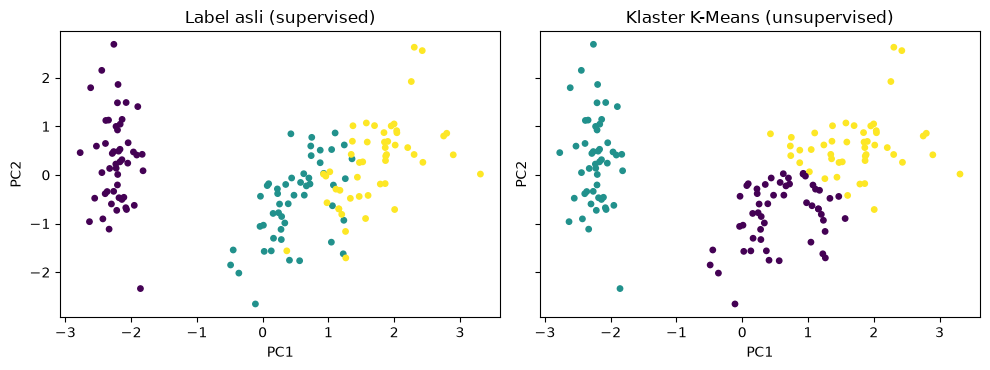

In [22]:
from sklearn.metrics import adjusted_rand_score

# --- Supervised: klasifikasi iris (pakai label) ---
sup = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000))
sup.fit(X_tr_i, y_tr_i)
print("[Supervised]   akurasi test LogisticRegression:", round(sup.score(X_te_i, y_te_i), 3))

# --- Unsupervised: K-Means pada iris (label TIDAK dipakai saat fit) ---
X_iris_s = StandardScaler().fit_transform(iris.data)
km = KMeans(n_clusters=3, n_init=10, random_state=RANDOM_STATE).fit(X_iris_s)
print("[Unsupervised] inertia_ K-Means:", round(km.inertia_, 2))
print("               ukuran klaster  :", np.bincount(km.labels_))
print("               ARI vs label asli (evaluasi eksternal):", round(adjusted_rand_score(iris.target, km.labels_), 3))
print("               transform -> jarak ke centroid, shape:", km.transform(X_iris_s).shape)

# --- Unsupervised: PCA untuk reduksi dimensi 4D -> 2D ---
pca = PCA(n_components=2, random_state=RANDOM_STATE)
X_pca = pca.fit_transform(X_iris_s)
print("[Unsupervised] explained_variance_ratio_ PCA:", pca.explained_variance_ratio_.round(3),
      "| total =", pca.explained_variance_ratio_.sum().round(3))

fig, axes = plt.subplots(1, 2, figsize=(10, 3.8), sharex=True, sharey=True)
axes[0].scatter(X_pca[:, 0], X_pca[:, 1], c=iris.target, cmap="viridis", s=15)
axes[0].set_title("Label asli (supervised)")
axes[1].scatter(X_pca[:, 0], X_pca[:, 1], c=km.labels_, cmap="viridis", s=15)
axes[1].set_title("Klaster K-Means (unsupervised)")
for ax in axes:
    ax.set_xlabel("PC1"); ax.set_ylabel("PC2")
plt.tight_layout(); plt.show()

**Interpretasi:** Model supervised memanfaatkan label dan mencapai akurasi test yang tinggi pada iris. K-Means, tanpa pernah melihat label, membagi data menjadi tiga klaster; nilai *Adjusted Rand Index* (ARI) sebesar 0.62 (1 = identik, 0 = setara acak) menunjukkan klaster cukup sesuai dengan spesies asli, walau tidak sempurna. Pada plot, kelas *setosa* terpisah sempurna, sedangkan *versicolor* dan *virginica* saling tumpang-tindih sehingga K-Means salah mengelompokkan sebagian titik di perbatasan keduanya. PCA memadatkan 4 fitur menjadi 2 komponen yang menjelaskan sebagian besar (~96%) variansi, memungkinkan visualisasi 2D. Perhatikan bahwa KMeans dan PCA tetap mengikuti API yang sama: `fit`, `predict`/`transform`, dan atribut hasil belajar seperti `inertia_` dan `explained_variance_ratio_`.

## Ringkasan Chapter 1

Chapter 1 tidak membahas algoritma tertentu, melainkan **kontrak antarmuka** yang membuat seluruh scikit-learn terasa seperti satu bahasa. Poin-poin utama:

**Filosofi desain**
- scikit-learn dibangun atas lima prinsip: *consistency*, *inspection*, *non-proliferation of classes*, *composition*, dan *sensible defaults*. Hasilnya, mengganti algoritma biasanya cukup dengan mengganti satu nama kelas.

**Data**
- `X` selalu 2D `(n_samples, n_features)`, `y` 1D `(n_samples,)`. Satu fitur tunggal harus di-`reshape(-1, 1)`.
- Input dapat berupa NumPy array, pandas DataFrame (nama kolom tersimpan di `feature_names_in_`), atau matriks sparse SciPy untuk data yang didominasi nol.
- `sklearn.datasets` menyediakan *loader* (`load_*`, mengembalikan `Bunch`; opsi `return_X_y` dan `as_frame`), *fetcher* (`fetch_*`), dan *generator* sintetis (`make_*`) yang dapat direproduksi via `random_state`.

**Tiga antarmuka inti**

| Antarmuka | Metode kunci | Contoh |
|---|---|---|
| Estimator | `fit`, `get_params`, `set_params` | Semua objek |
| Predictor | `predict`, `predict_proba`, `decision_function`, `score` | `LogisticRegression`, `KMeans` |
| Transformer | `fit`, `transform`, `fit_transform`, `inverse_transform` | `StandardScaler`, `PCA`, `OneHotEncoder` |

- Hyperparameter ditetapkan di `__init__`; parameter hasil belajar disimpan di atribut ber-akhiran `_` dan baru ada setelah `fit`. `fit` mengembalikan `self`.
- `clone()` menghasilkan salinan dengan hyperparameter sama tetapi belum dilatih.
- `score` default: akurasi untuk classifier, $R^2$ untuk regressor.

**Evaluasi yang jujur**
- Selalu pisahkan data dengan `train_test_split` (gunakan `random_state` dan `stratify` untuk data tidak seimbang).
- Statistik preprocessing hanya boleh dipelajari dari data latih (`fit_transform` pada train, `transform` pada test) untuk menghindari **data leakage**.
- Gap besar antara skor train dan test menandakan *overfitting*.

**Komposisi**
- `Pipeline` / `make_pipeline` merangkai transformer dan estimator menjadi satu objek; aman dari leakage dalam cross-validation dan mendukung tuning dengan notasi `langkah__parameter`.
- `ColumnTransformer` menerapkan preprocessing berbeda untuk kolom numerik dan kategorikal, lalu menggabungkannya.

**Utilitas**
- `set_output(transform="pandas")` mempertahankan nama kolom setelah transformasi; `set_config` / `config_context` mengatur perilaku global (tampilan diagram HTML, `print_changed_only`, dll.).
- `joblib.dump` / `joblib.load` menyimpan pipeline utuh; catat versi scikit-learn dan jangan memuat file dari sumber tak tepercaya.

**Paradigma**
- Supervised learning memakai `fit(X, y)` untuk klasifikasi/regresi; unsupervised memakai `fit(X)` untuk clustering (K-Means) dan reduksi dimensi (PCA) — dengan API yang tetap sama.

> **Key takeaway:** Kuasai pola `Estimator().fit(X_train, y_train)` → `predict/transform(X_test)` → `score`, bungkus preprocessing dalam `Pipeline`, dan selalu evaluasi pada data yang tidak dipakai untuk training. Pola ini akan dipakai berulang di seluruh chapter berikutnya.